# Lab 11: MCMC and the 2D Ising model

A spin interacts with its four neighbors. We'll use that local rule to sample a whole lattice, then see what changes when we raise the temperature.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

plt.rcParams.update({
    "font.size": 13,
    "figure.figsize": (6.2, 3.5),
    "figure.dpi": 100,
    "figure.constrained_layout.use": True,
})
J = 1.0
KB = 1.0

We'll use NumPy for the lattice and Matplotlib for the plots. Run the cells in order; the later simulations use the functions we define along the way.

## What we're calling a spin

A **magnetic moment** has a direction and responds to a magnetic field. We represent its two allowed orientations along one axis by $+1$ and $-1$.

This is a classical model for magnetic order. The sites stay fixed; only the magnetic-moment orientations change. It doesn't calculate electrons moving through the material.

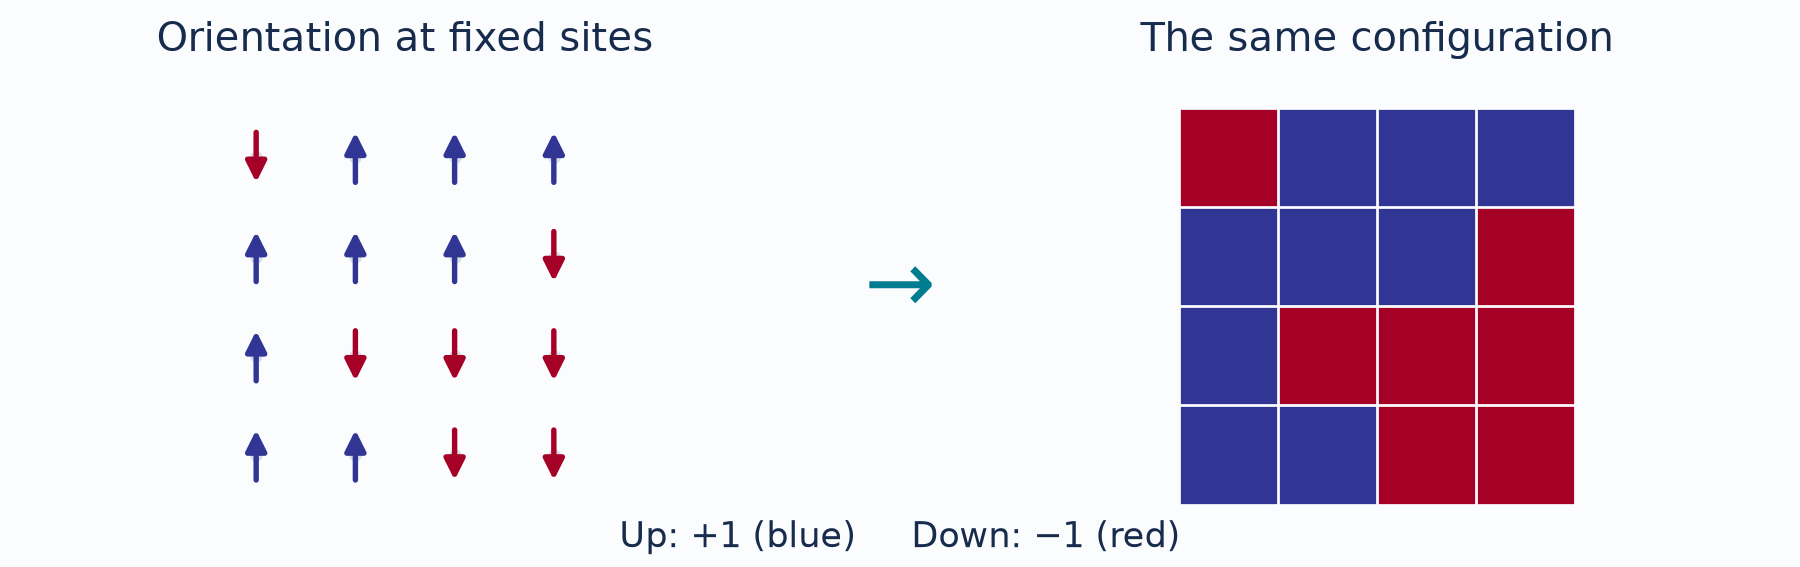

## What we're simulating

Some materials keep a net magnetization even without an applied magnetic field. Heating can destroy that order.

The Ising model keeps a small part of that physics: fixed sites, two orientations, and an interaction between neighboring sites. Here neighbors prefer to align. We apply no magnetic field, so neither up nor down is preferred.

We'll sample configurations at a fixed temperature and measure their magnetization. This lets us see how a rule involving just a few neighbors produces behavior across a whole system.

## Put the spins on a grid

Each entry is $+1$ or $-1$. Here $N$ is the side length, so the lattice contains $N^2$ spins. This is the configuration from lecture.

One square is one site, and the color gives its orientation. The whole array is one **configuration** of the system.

In [ ]:
N = 10
spins = np.ones((N, N), dtype=int)
spins[:5, :] = -1
spins[1, 3] = 1

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.imshow(spins, cmap="RdYlBu", vmin=-1, vmax=1)
ax.set_xticks(np.arange(-0.5, N, 1), minor=True)
ax.set_yticks(np.arange(-0.5, N, 1), minor=True)
ax.grid(which="minor", color="black", linewidth=0.3)
ax.set(title="Blue: +1     Red: −1", xlabel="Column", ylabel="Row")
plt.show()

## Neighbors and energy

With $J>0$, matching neighbors have lower energy than mismatched neighbors. Both up-up and down-down are equally favorable.

Here $J$ sets the strength of the interaction. A **bond** means one neighboring pair; we'll add its energy once.

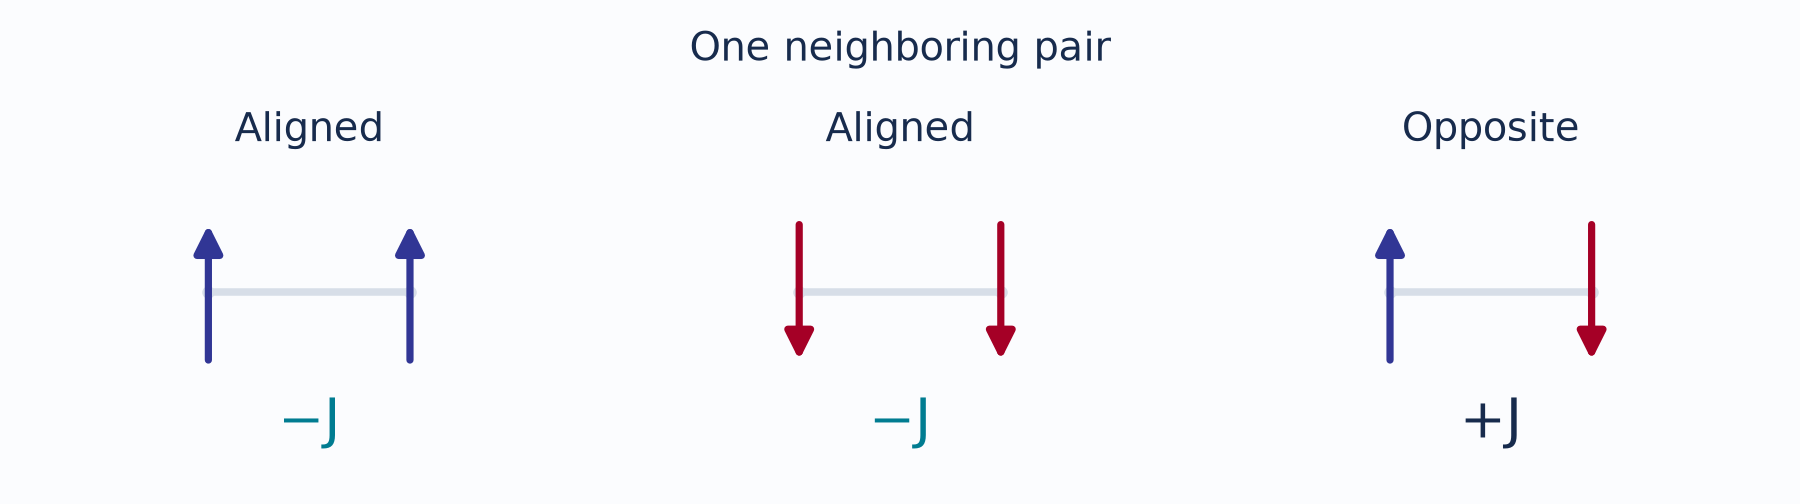

## Count each bond once

$$E=-J\sum_{\langle ij\rangle}\sigma_i\sigma_j.$$

Aligned neighbors contribute $-J$; opposite neighbors contribute $+J$. The edges wrap around. Summing all four neighbors counts every bond twice, so we divide by two.

In [ ]:
def total_energy(spins):
    n = spins.shape[0]
    energy = 0.0
    for i in range(n):
        for j in range(n):
            for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                neighbor = spins[(i + di) % n, (j + dj) % n]
                energy -= J * spins[i, j] * neighbor
    return energy / 2

print("Energy:", total_energy(spins))

For this configuration, the energy is −152 with $J=1$. The `% n` keeps the neighbor index inside the lattice, including at the edges.

## The edges are bookkeeping

We use **periodic boundaries**: the left edge connects to the right edge, and the top connects to the bottom. An edge site still has four neighbors.

This avoids giving edge sites fewer interactions. The arrows show which sites count as neighbors; no particle travels across the picture.

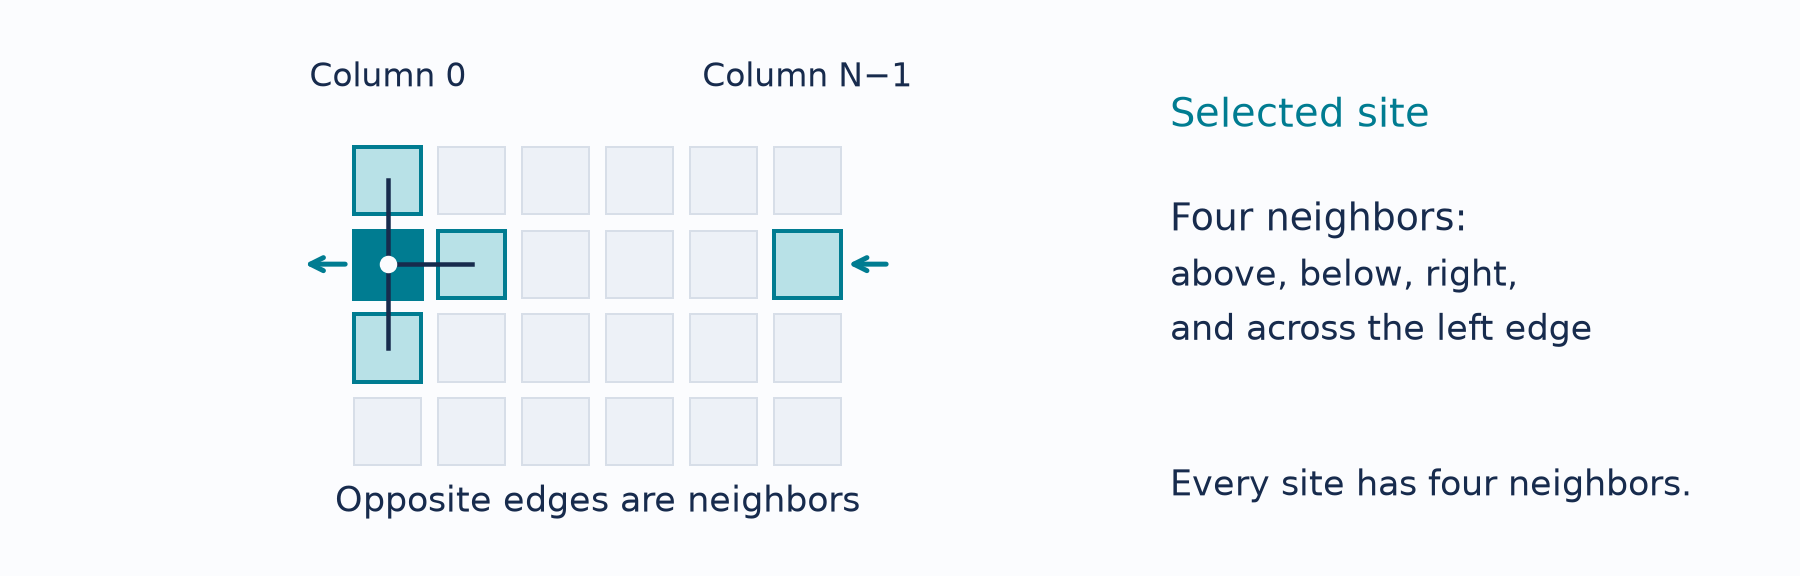

## Why sample configurations?

Even our $24\times24$ lattice has $2^{576}$ possible configurations. We can't list them all and calculate a weighted average directly.

Instead, we build a **Markov chain**: propose a change to the current configuration, accept or reject it, and repeat. The next update uses the current lattice.

The acceptance rule makes the long-run frequencies match the thermal probabilities. After the chain has settled, averages along the chain estimate averages over those probabilities. Nearby samples are still correlated.

## Temperature changes the probabilities

We're modeling a material in contact with surroundings held at temperature $T$. They can exchange energy; the energy of our spin lattice need not stay constant.

Lower-energy configurations are more likely **individually**. But there are far more mixed configurations than fully aligned ones. Raising the temperature makes energy increases less costly, so that large number of mixed configurations matters more.

Below is the chance of accepting one proposed energy increase. An energy decrease is always accepted.

In [ ]:
temperature_axis = np.linspace(0.5, 4.0, 150)
fig, ax = plt.subplots()
for cost, color in [(4 * J, "#007c91"), (8 * J, "#a54632")]:
    probability = np.exp(-cost / (KB * temperature_axis))
    ax.plot(temperature_axis, probability,
            color=color, label=f"Energy rises by {cost:g} J")
ax.axhline(1, color="gray", linestyle="--", label="Energy falls or stays the same")
ax.set(xlabel="Temperature T (J = kB = 1)",
       ylabel="Probability of accepting the flip", ylim=(0, 1.05))
ax.legend(fontsize=10)
plt.show()

## Flip one spin

Only the four bonds touching that spin change. In the picture, the central spin initially disagrees with all four neighbors. Flipping it makes all four bonds favorable.

Those bonds go from a total of $+4J$ to $-4J$: the energy falls by $8J$. The rest of the lattice contributes the same energy before and after, so we don't need to recompute it.

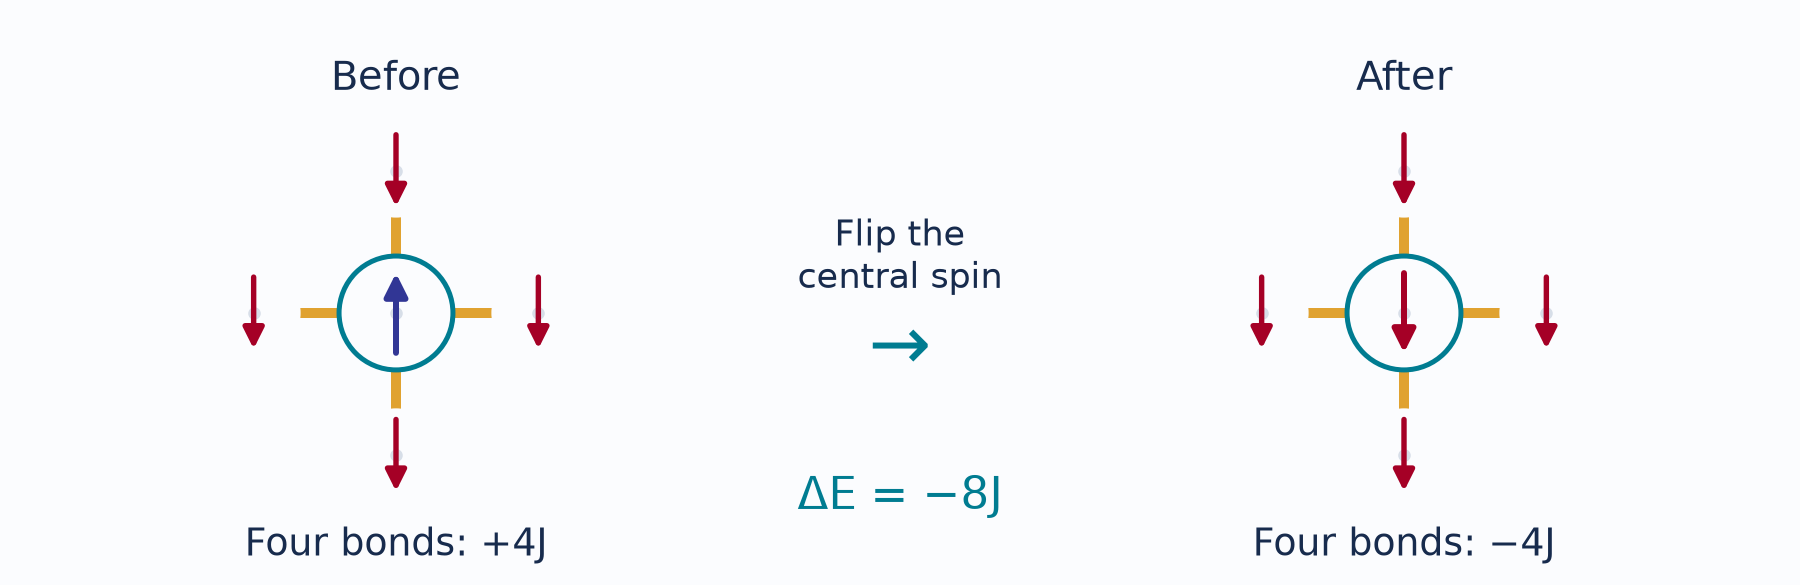

## Calculate the change locally

The function adds the four neighbor values, then uses the current spin to get the energy change. The calculation is the same at every site, including the edges.

In [ ]:
@njit
def flip_energy(spins, i, j):
    n = spins.shape[0]
    neighbors = spins[(i - 1) % n, j] + spins[(i + 1) % n, j] + spins[i, (j - 1) % n] + spins[i, (j + 1) % n]
    return 2 * J * spins[i, j] * neighbors

print("Flip the isolated +1 spin:", flip_energy(spins, 1, 3))

## Accept or reject

We choose a site uniformly, so proposing the reverse flip is equally likely.

- **Energy falls or stays the same:** accept.
- **Energy rises:** accept with probability $e^{-\Delta E/(k_{\mathrm B}T)}$.

A rejected proposal leaves the lattice unchanged. It still counts as a step. Keeping those repeated configurations is part of getting the sampling probabilities right.

In [ ]:
@njit
def metropolis_step(spins, temperature, rng):
    i, j = rng.integers(0, spins.shape[0], size=2)
    delta_energy = flip_energy(spins, i, j)
    if delta_energy <= 0 or rng.random() < np.exp(-delta_energy / (KB * temperature)):
        spins[i, j] *= -1
        return 1
    return 0

## Magnetization

The total magnetization $M$ is the sum of the spins. We'll plot the magnetization per spin, $m$: divide that sum by the number of sites. In Python, that's `spins.mean()`.

All spins up gives $m=1$; all down gives $m=-1$. A nearly equal mix gives $m\approx0$.

That average doesn't tell us how the spins are arranged. Both pictures below have $m=0$, but very different neighbor interactions. The checkerboard is a constructed example, not a typical hot configuration.

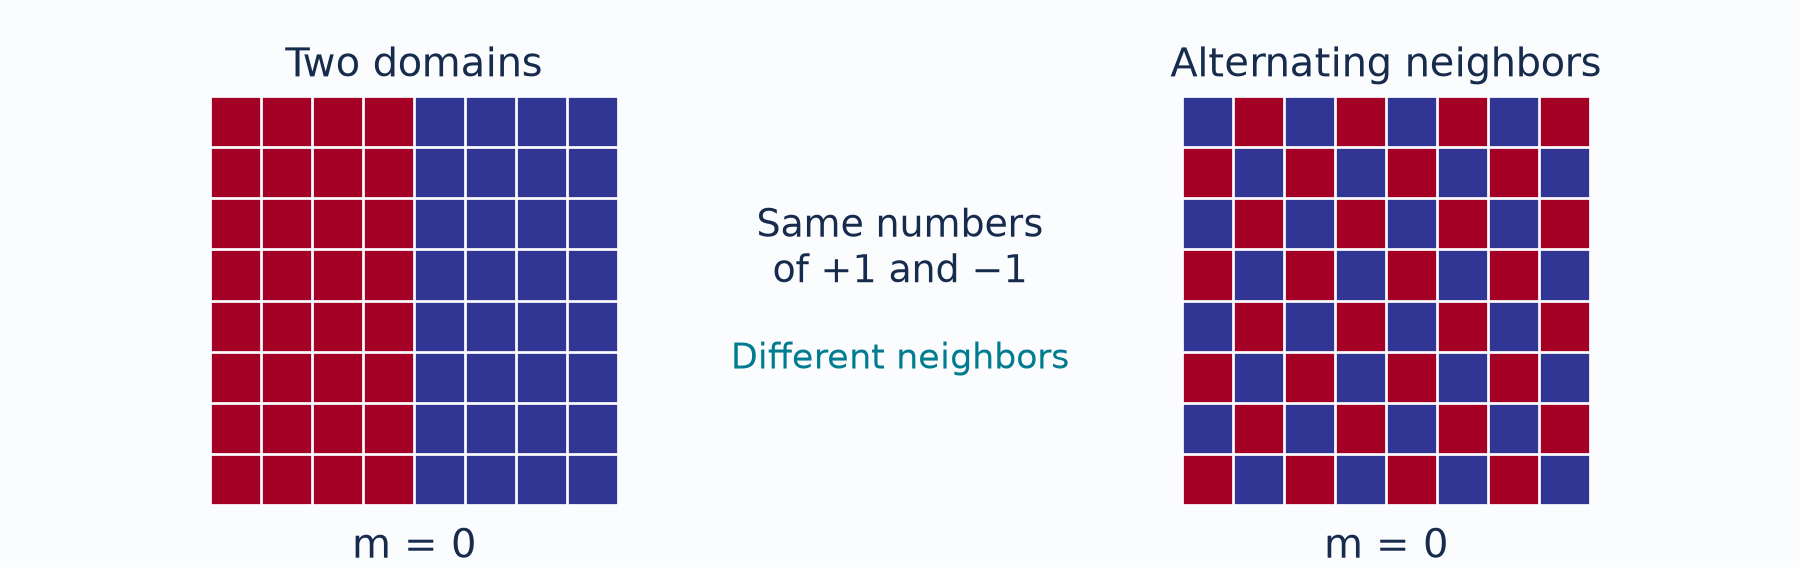

## Count time in sweeps

One **sweep** is $N^2$ attempted flips. Sites are chosen randomly, so some can be chosen more than once.

We'll start with all spins up and record $m$ after each sweep, whether the proposals were accepted or rejected. The seed makes a run reproducible.

This is a sampling clock. A sweep does not correspond to a specified number of seconds in a real magnet.

## Repeat the update

The inner loop attempts one sweep. The outer loop repeats it and records the magnetization. `run_ising` sets up the lattice and random generator.

In [ ]:
@njit
def advance_ising(spins, temperature, sweeps, rng):
    n = spins.shape[0]
    magnetization = np.empty(sweeps + 1)
    magnetization[0] = spins.mean()
    accepted = 0
    for sweep in range(1, sweeps + 1):
        for _ in range(n * n):
            accepted += metropolis_step(spins, temperature, rng)
        magnetization[sweep] = spins.mean()
    return (magnetization, accepted)


def run_ising(temperature, n, sweeps, seed):
    rng = np.random.default_rng(seed)
    spins = np.ones((n, n), dtype=int)
    magnetization, accepted = advance_ising(spins, temperature, sweeps, rng)
    return (spins, magnetization, accepted / (sweeps * n * n))

## Compile before the larger runs

The short energy calculation above is ordinary Python. The repeated flip and sweep loops use Numba's `@njit`, which compiles them to machine code.

We'll make one tiny throwaway run now to pay the compilation cost. Later runs reuse that compiled code. Python still handles setup and plotting.

The updates remain sequential: each accepted flip changes the neighbors seen by later proposals. Updating the whole grid at once would change the algorithm.

In [ ]:
# Compile with the same array dtype and temperature type as the larger runs.
_ = run_ising(2.0, n=4, sweeps=1, seed=0)

## Run at $T=2$

Use $J=k_{\mathrm B}=1$ and a $24\times24$ lattice to keep the live calculation short. The acceptance rate is the fraction of proposed flips that changed a spin.

In [ ]:
N = 24
SWEEPS = 400
SEED = 142
T = 2.0

final_spins, m_values, acceptance = run_ising(T, N, SWEEPS, SEED)
print(f"Attempted flips: {SWEEPS * N * N:,}")
print(f"Acceptance rate: {acceptance:.3f}")

## Look at the lattice

This is one configuration at the end of the run. Each patch of the same color is a group of aligned spins.

We'll also look at the history of the magnetization, since a final picture doesn't tell us how the chain got there.

In [ ]:
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.imshow(final_spins, cmap="RdYlBu", vmin=-1, vmax=1)
ax.set(title=f"T = {T}, after {SWEEPS} sweeps",
       xlabel="Column", ylabel="Row")
plt.show()

## Follow the magnetization

The chain starts at $m=1$ because we put every spin up. That is our starting choice, not a measurement of equilibrium.

We'll set aside the first 100 sweeps as **burn-in** for this demonstration. That cutoff is a choice to inspect, not a guarantee that the chain has equilibrated.

In [ ]:
BURNIN = 100
sweep_axis = np.arange(SWEEPS + 1)

fig, ax = plt.subplots()
ax.plot(sweep_axis, m_values, color="#007c91")
ax.axvspan(0, BURNIN, color="gray", alpha=0.2, label="Burn-in")
ax.axvline(BURNIN, color="gray", linestyle="--")
ax.set(xlabel="Sweeps", ylabel="Magnetization per spin m",
       title=f"T = {T}", ylim=(-1.05, 1.05))
ax.legend()
plt.show()

## After burn-in

We'll summarize the values after the cutoff. The standard deviation measures how much $m$ fluctuates; it is **not the uncertainty on the mean**. Consecutive measurements can still be correlated.

In [ ]:
samples = m_values[BURNIN + 1:]
print(f"Mean m: {samples.mean():.3f}")
print(f"Standard deviation of m: {samples.std():.3f}")
print(f"Mean |m|: {np.abs(samples).mean():.3f}")

The mean of `abs(m)` measures net alignment without favoring up over down. It differs from taking `abs` after the mean: positive and negative magnetization can cancel when the chain switches sign.

Neither number describes the whole spatial pattern. That's why we keep the lattice pictures as well as the averages.

## Raise the temperature

For the infinite square lattice with no applied magnetic field, the critical temperature is about **2.269** in our units ($J=k_{\mathrm B}=1$).

Below it, the system can sustain net alignment without a field choosing the direction. Above it, that bulk order disappears. There can still be aligned neighbors and small patches.

Our finite lattice shows a rounded version of this change. These temperatures are in units set by the interaction strength; they are not kelvin values for a particular material.

## Compare three temperatures

We'll run below, near, and above $T_{\mathrm c}$ with the same lattice size and number of sweeps. Each run starts from all spins up.

The neighbor rule is unchanged. Temperature only changes how often we accept a move that raises the energy.

In [ ]:
temperatures = [1.5, 2.269, 3.5]
runs = {}
for index, temperature in enumerate(temperatures):
    runs[temperature] = run_ising(temperature, N, SWEEPS, SEED + index)
    _, history, rate = runs[temperature]
    mean_abs_m = np.abs(history[BURNIN + 1:]).mean()
    print(f"T = {temperature:.3f}: mean |m| = {mean_abs_m:.3f}, "
          f"acceptance = {rate:.3f}")

## The final configurations

At low temperature, large regions tend to align. At high temperature, energy-increasing flips are accepted more often and that order breaks up.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 3.0))
for ax, temperature in zip(axes, temperatures):
    lattice, _, _ = runs[temperature]
    ax.imshow(lattice, cmap="RdYlBu", vmin=-1, vmax=1)
    ax.set(title=f"T = {temperature:g}", xticks=[], yticks=[])
plt.show()

## The histories matter too

Near the transition, relaxation can be slow. These short runs show temperature dependence on a finite lattice; they do not locate the critical temperature precisely.

In [ ]:
fig, ax = plt.subplots()
for temperature in temperatures:
    _, history, _ = runs[temperature]
    ax.plot(sweep_axis, history, label=f"T = {temperature:g}")
ax.axvspan(0, BURNIN, color="gray", alpha=0.2)
ax.set(xlabel="Sweeps", ylabel="Magnetization per spin m",
       ylim=(-1.05, 1.05))
ax.legend()
plt.show()

## Prepare the temperature comparison

We'll calculate each run once and save its final lattice and magnetization history. The plotting code builds a set of views we can move between on the next slide.

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Each entry is a separate simulation, with the same start and random seed.
temperature_grid = [1.0, 1.5, 2.0, 2.269, 2.5, 3.0, 3.5, 4.0]
saved_runs = [run_ising(temp, 64, 400, 142) for temp in temperature_grid]

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.3))
lattice_image = axes[0].imshow(saved_runs[0][0], cmap="RdYlBu", vmin=-1, vmax=1)
axes[0].set(xticks=[], yticks=[])
history_line, = axes[1].plot(saved_runs[0][1], color="#007c91")
axes[1].set(xlabel="Sweeps", ylabel="Magnetization per spin m", ylim=(-1.05, 1.05))

def show_temperature(index):
    lattice, history, rate = saved_runs[index]
    lattice_image.set_data(lattice)
    history_line.set_ydata(history)
    axes[0].set_title(f"T = {temperature_grid[index]:g}; final lattice")
    axes[1].set_title(f"Accepted: {rate:.1%}")
    return lattice_image, history_line

# The slider selects among the saved temperatures, not times in one run.
temperature_comparison = FuncAnimation(
    fig, show_temperature, frames=len(temperature_grid), interval=900, repeat=False)
temperature_html = temperature_comparison.to_jshtml(default_mode="once")
plt.close(fig)

## Compare saved temperature runs

The slider selects among eight temperatures, including $T=2.269$. Each picture comes from a separate $64\times64$ run of 400 sweeps, starting with all spins up and the same random seed.

Run this cell to show the comparison. Use the slider or arrow buttons to move between saved runs. The left panel is the final configuration; the right panel is its magnetization history.

This is precomputed playback across temperatures, not time in one sample. Near the transition, 400 sweeps can still be too short to forget the starting state.

In [ ]:
display(HTML(temperature_html))

## From a local flip to a thermal average

We used four neighbors to calculate $\Delta E$, accepted or rejected a flip, and repeated that rule across the lattice.

Each update only sees four neighbors. Those interactions can sustain order across the system.

The temperature sets how readily the system accepts an energy increase. The magnetization shows the resulting net alignment, while its history and the lattice pictures tell us what one average leaves out.

### References

- [Ising models and magnetic order: David Tong, Statistical Field Theory, section 1.1](https://www.damtp.cam.ac.uk/user/tong/sft/sfthtml/S1.html).
- [Numba's support for NumPy random generators](https://numba.readthedocs.io/en/stable/reference/numpysupported.html#generator-objects).
- [Matplotlib's self-contained HTML animation controls](https://matplotlib.org/stable/api/_as_gen/matplotlib.animation.Animation.html#matplotlib.animation.Animation.to_jshtml).

Run the comparison cell to create its saved views and controls. The static plots above remain available in the exported lab page.